# Evolution of VoteRank-based Methods for Influence Maximization on Complex Networks

**Authors:** Iván Pintó Varona e Izan Abia Sainz[cite: 1]

Este cuaderno ejecuta la evaluación experimental importando los módulos limpios desde `src/`.

In [6]:
import sys
import os
import random
import time
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ajustar ruta para importar desde src/
sys.path.append(os.path.abspath(os.path.join('..')))

from src.utils import ensure_weighted
from src.diffusion import independent_cascade, average_spread
from src.models import vote_rank, w_vote_rank, iw_vote_rank, rwr, rwr_with_wvr_optionA

## 1. Generación de la Red y Evaluación de Propagación ($k = 10$)

Para simular la estructura de libre escala típica de los sistemas complejos del mundo real, generamos una red sintética ponderada utilizando el modelo de **Barabási–Albert**. 

Posteriormente, evaluamos la propagación de influencia mediante el modelo de cascada independiente (*Independent Cascade - IC*) fijando una probabilidad de propagación pequeña y constante. Comparamos el rendimiento inicial de los métodos VoteRank clásico, ponderado (WVoteRank) y mejorado a 2-saltos (IWVoteRank).

In [7]:
random.seed(42)
G = nx.barabasi_albert_graph(500, 3)

for u, v, d in G.edges(data=True):
    d['weight'] = random.random()
    d['prob'] = 0.05   # Probabilidad fija pequeña

k = 10
seeds_vr = vote_rank(G, k)
seeds_wvr = w_vote_rank(G, k)
seeds_iwvr = iw_vote_rank(G, k)

spread_vr = average_spread(G, seeds_vr, p_attr='prob')
spread_wvr = average_spread(G, seeds_wvr, p_attr='prob')
spread_iwvr = average_spread(G, seeds_iwvr, p_attr='prob')

df_k10 = pd.DataFrame([
    ["VoteRank", spread_vr],
    ["WVoteRank", spread_wvr],
    ["IWVoteRank", spread_iwvr]
], columns=["Method", "Spread"])

display(df_k10)

,Method,Spread
0,VoteRank,36.495
1,WVoteRank,36.920
2,IWVoteRank,35.535


## 2. Análisis de Escalabilidad y Tiempos de Ejecución

Para profundizar en el comportamiento de los algoritmos, analizamos cómo varía el alcance de la influencia (*Influence Spread*) y el coste computacional (tiempo de ejecución en segundos) al incrementar el número de nodos semilla $k \in \{5, 10, 15, 20\}$. 

Esto permite contrastar la ganancia marginal de influencia frente al incremento de complejidad temporal introducido por las variantes avanzadas (como la exploración de 2-hops en IWVoteRank).

In [8]:
k_values = [5, 10, 15, 20]
results = []
timing_results = []

for k in k_values:
    # Spread
    seeds_vr = vote_rank(G, k)
    seeds_wvr = w_vote_rank(G, k)
    seeds_iwvr = iw_vote_rank(G, k)

    results.append(["VoteRank", k, average_spread(G, seeds_vr, p_attr='prob')])
    results.append(["WVoteRank", k, average_spread(G, seeds_wvr, p_attr='prob')])
    results.append(["IWVoteRank", k, average_spread(G, seeds_iwvr, p_attr='prob')])

    # Tiempos
    start = time.time(); vote_rank(G, k); t_vr = time.time() - start
    start = time.time(); w_vote_rank(G, k); t_wvr = time.time() - start
    start = time.time(); iw_vote_rank(G, k); t_iwvr = time.time() - start

    timing_results.append(["VoteRank", k, t_vr])
    timing_results.append(["WVoteRank", k, t_wvr])
    timing_results.append(["IWVoteRank", k, t_iwvr])

df_multi = pd.DataFrame(results, columns=["Method", "k", "Spread"])
df_time = pd.DataFrame(timing_results, columns=["Method", "k", "Execution Time (s)"])

display(df_multi)
display(df_time)

,Method,k,Spread
0,VoteRank,5,24.800
1,WVoteRank,5,25.110
2,IWVoteRank,5,24.135
3,VoteRank,10,36.830
4,WVoteRank,10,37.030
5,IWVoteRank,10,35.425
6,VoteRank,15,46.435
7,WVoteRank,15,45.265
8,IWVoteRank,15,44.890
9,VoteRank,20,53.585


,Method,k,Execution Time (s)
0,VoteRank,5,0.005015
1,WVoteRank,5,0.010549
2,IWVoteRank,5,0.083013
3,VoteRank,10,0.007090
4,WVoteRank,10,0.016643
5,IWVoteRank,10,0.162982
6,VoteRank,15,0.009046
7,WVoteRank,15,0.022826
8,IWVoteRank,15,0.228881
9,VoteRank,20,0.011301


### Visualización Comparativa del Spread

A continuación, representamos gráficamente el promedio de influencia alcanzada por cada variante en función del número de semillas $k$.

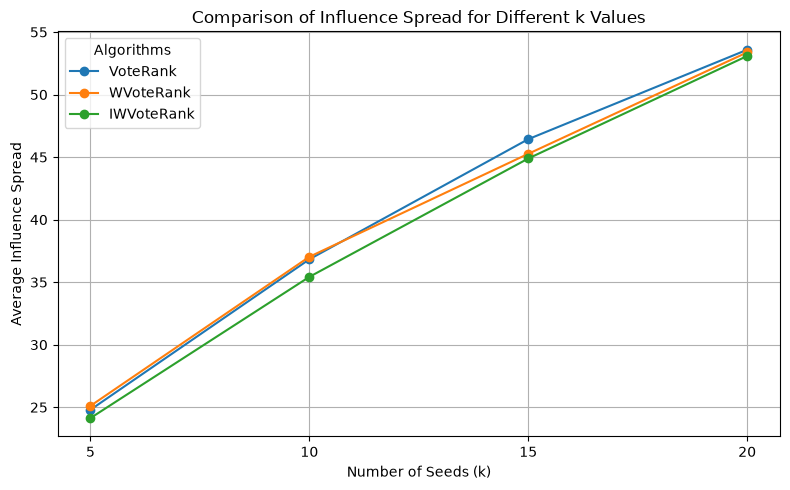

In [9]:
plt.figure(figsize=(8, 5))
for method in df_multi["Method"].unique():
    subset = df_multi[df_multi["Method"] == method]
    plt.plot(subset["k"], subset["Spread"], marker='o', linestyle='-', label=method)

plt.xlabel("Number of Seeds (k)")
plt.ylabel("Average Influence Spread")
plt.title("Comparison of Influence Spread for Different k Values")
plt.xticks(sorted(df_multi["k"].unique()))
plt.grid(True)
plt.legend(title="Algorithms")
plt.tight_layout()
plt.show()

## 3. Random Walk with Restart (RWR) y Activación Estructural (WVotedRank)

En esta sección implementamos *Random Walk with Restart* (RWR) para propagar la relevancia desde un nodo semilla seleccionado a lo largo del grafo ponderado hasta alcanzar la convergencia en estado estacionario. 

Para refinar el ranking, integramos RWR con una puntuación de activación estructural inspirada en WVotedRank:
$$\text{FinalScore}(v) = \text{RWR}(v) \cdot \text{WVotedRank}(v)$$

Finalmente, comparamos los 10 nodos principales obtenidos mediante RWR puro frente a la aproximación híbrida para medir la estabilidad y el impacto estructural de la combinación.

In [10]:
seeds = w_vote_rank(G, k=10)
seed = seeds[0]

rwr_scores = rwr(G, seed)
rwr_wvr_scores = rwr_with_wvr_optionA(G, seed)

top_rwr = sorted(rwr_scores.items(), key=lambda x: x[1], reverse=True)[:10]
top_rwr_wvr = sorted(rwr_wvr_scores.items(), key=lambda x: x[1], reverse=True)[:10]

print("Top 10 RWR:", top_rwr)
print("\nTop 10 RWR + WVotedRank:", top_rwr_wvr)

Top 10 RWR: [(4, np.float64(0.19740336558495006)), (5, np.float64(0.015067886541058359)), (6, np.float64(0.014219675416906262)), (7, np.float64(0.013513272351712418)), (12, np.float64(0.01216373692767134)), (0, np.float64(0.011434099579326364)), (25, np.float64(0.011120414538125276)), (10, np.float64(0.009058524982279428)), (56, np.float64(0.00897382002449008)), (20, np.float64(0.008020657614337207))]

Top 10 RWR + WVotedRank: [(4, np.float64(9.186115726814599)), (6, np.float64(0.6543599222800087)), (5, np.float64(0.632475720908098)), (7, np.float64(0.5637710383453934)), (12, np.float64(0.32723869447941045)), (0, np.float64(0.291272755969027)), (3, np.float64(0.20806744071656447)), (10, np.float64(0.20427975258847092)), (25, np.float64(0.17128041357786103)), (34, np.float64(0.15940413052074537))]


## 4. Conclusiones y Discusión

- **Maximización de Influencia:** El spread de influencia aumenta de forma consistente conforme incrementamos $k$. En redes de libre escala, las diferencias de rendimiento entre las variantes de VoteRank se mantienen moderadas.
- **Coste Computacional:** IWVoteRank incrementa el tiempo de ejecución debido a la evaluación de vecindarios a 2-hop.
- **Integración con RWR:** La combinación de caminos aleatorios con la activación estructural de WVotedRank preserva una alta estabilidad en los rankings (con una intersección notable en el Top-10), logrando reordenar los candidatos de manera óptima sin perder localidad.